# Complaint Pattern Analysis of Mumbai BMC Civic Complaints
## Data Warehousing & Data Mining (CSI3010) — Lab Project Week 1 Implementation

---

### Project Overview
The **Brihanmumbai Municipal Corporation (BMC)** is India's richest municipal corporation, serving over 12 million residents across 24 administrative wards. This project builds an enterprise **Data Warehouse (Star Schema)** to analyze civic complaints lodged between 2018 and 2024, enabling multidimensional OLAP analytics and establishing the foundation for data mining tasks.

### Week 1 Workflow Pipeline:
$$\text{Dataset Inspection} \longrightarrow \text{Data Profiling} \longrightarrow \text{Data Cleaning} \longrightarrow \text{Star Schema Design} \longrightarrow \text{MySQL DDL} \longrightarrow \text{Python ETL} \longrightarrow \text{Validation} \longrightarrow \text{5 OLAP Operations}$$


## 1. Environment Setup & Library Imports
We import standard data science, visualization, database connectors, and configuration management libraries.

In [1]:
import os
import sys
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv

# Set plotting theme
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

print("All required packages imported successfully!")


All required packages imported successfully!


## 2. Database Connection Configuration
We read database credentials securely from `.env` using `python-dotenv` without hardcoding sensitive passwords. We use SQLAlchemy with `pymysql` driver and `URL.create` to handle special characters cleanly.

In [2]:
# Locate .env from root or parent directory
env_path = ".env" if os.path.exists(".env") else os.path.join("..", ".env")
load_dotenv(env_path)

DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = int(os.getenv("DB_PORT", "3306"))
DB_USER = os.getenv("DB_USER", "root")
DB_PASSWORD = os.getenv("DB_PASSWORD", "")
DB_NAME = os.getenv("DB_NAME", "bmc_complaint_dw")

# Construct robust connection URL
db_url = URL.create(
    drivername="mysql+pymysql",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME
)
engine = create_engine(db_url)

with engine.connect() as conn:
    version = conn.execute(text("SELECT VERSION();")).scalar()
    print(f"Connected to MySQL Server {version} at {DB_HOST}:{DB_PORT}/{DB_NAME}")


Connected to MySQL Server 8.0.43 at localhost:3306/bmc_complaint_dw


## 3. Data Extraction & Dataset Inspection
We load the raw CSV files from `dataset/` using relative paths.
We inspect:
- `bmc_train.csv`: Primary ground-truth civic complaints dataset (960,000 records, 35 attributes)
- `bmc_data_dictionary.csv`: Supporting metadata reference describing all attributes
- `bmc_test.csv`: 240,000 held-out evaluation records (target withheld)
- `bmc_sample_submission.csv`: Evaluation template

In [3]:
# Locate dataset directory
data_dir = "dataset" if os.path.exists("dataset") else os.path.join("..", "dataset")

t0 = time.time()
raw_train_path = os.path.join(data_dir, "bmc_train.csv")
dict_path = os.path.join(data_dir, "bmc_data_dictionary.csv")

df_raw = pd.read_csv(raw_train_path)
df_dict = pd.read_csv(dict_path)

print(f"Loaded {len(df_raw):,} records from '{raw_train_path}' in {time.time()-t0:.2f} seconds.")
print(f"Data Dictionary loaded with {len(df_dict)} feature definitions.")
display(df_dict.head(10))


Loaded 960,000 records from '..\dataset\bmc_train.csv' in 4.03 seconds.
Data Dictionary loaded with 35 feature definitions.


,feature,dtype,description
0,complaint_id,string,Unique complaint ID (ward+year+seq)
1,complaint_date,date,Date complaint was filed
2,year,int,Year (2018–2024)
3,month,int,Month (1–12)
4,is_monsoon_season,int,1 if June–September
5,complaint_time_of_day,string,Time band when complaint filed
6,ward_code,string,BMC administrative ward (A to T)
7,ward_area,string,Locality name of ward
8,zone,string,BMC zone (City/Eastern/Western)
9,ward_type,string,South / Central / Suburban


## 4. Comprehensive Data Profiling
We inspect:
- Dimensions (`shape`)
- First 5 rows (`head()`)
- Schema types (`info()`)
- Descriptive statistics (`describe()`)
- Missing value audit
- Duplicate record count
- Unique value analysis across dimensions

In [4]:
print(f"Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print("\n--- First 5 Records ---")
display(df_raw.head())

print("\n--- Missing Values Audit ---")
missing_series = df_raw.isnull().sum()
print("Missing values per column:")
display(missing_series[missing_series > 0] if missing_series.sum() > 0 else "Zero missing values detected across all 35 columns.")

print("\n--- Duplicate Analysis ---")
print(f"Exact Duplicate Rows: {df_raw.duplicated().sum()}")
print(f"Duplicate Complaint IDs: {df_raw['complaint_id'].duplicated().sum()}")

print("\n--- Descriptive Statistics for Numeric Features ---")
num_cols = ["resolution_days", "estimated_cost_inr", "num_reassignments", "prior_complaints_count", "infrastructure_age_years"]
display(df_raw[num_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]])


Dataset Shape: 960,000 rows x 35 columns

--- First 5 Records ---


,complaint_id,complaint_date,year,month,is_monsoon_season,complaint_time_of_day,ward_code,ward_area,zone,ward_type,...,num_reassignments,complaint_status,contractor_category,work_quality_rating,site_inspected,defect_liability_claim,estimated_cost_inr,infrastructure_age_years,months_since_last_maintained,citizen_satisfied
0,BMC20240942049,2024-09-20,2024,9,1,Evening (5-9pm),A,Colaba-Fort,City,South,...,2,Resolved,Class C (Small),Good,1,0,1500,2,8,1
1,BMC20240088068,2024-01-02,2024,1,0,Daytime (10am-5pm),P/N,Malad,Western,Suburban,...,1,Resolved,Class B (Medium),Fair,0,0,38600,0,3,0
2,BMC20220421176,2022-04-12,2022,4,0,Daytime (10am-5pm),B,Mandvi-Masjid,City,South,...,1,Resolved,Class A (Large),Fair,1,1,13000,10,21,1
3,BMC20240073658,2024-02-28,2024,2,0,Evening (5-9pm),M/E,Govandi-Mankhurd,Eastern,Suburban,...,0,Closed Without Resolution,Class C (Small),Fair,0,0,2400,20,15,0
4,BMC20190483987,2019-03-15,2019,3,0,Daytime (10am-5pm),L,Kurla-Vidyavihar,Eastern,Suburban,...,3,Resolved,Class C (Small),Good,0,0,11400,40,59,1



--- Missing Values Audit ---


Missing values per column:


'Zero missing values detected across all 35 columns.'


--- Duplicate Analysis ---


Exact Duplicate Rows: 0


Duplicate Complaint IDs: 0

--- Descriptive Statistics for Numeric Features ---


,mean,std,min,25%,50%,75%,max
resolution_days,13.733475,13.678198,1.0,5.0,10.0,18.0,210.0
estimated_cost_inr,10939.766979,12632.199695,500.0,3100.0,6500.0,14000.0,324900.0
num_reassignments,1.030672,1.244879,0.0,0.0,1.0,2.0,5.0
prior_complaints_count,1.002811,1.780709,0.0,0.0,0.0,2.0,14.0
infrastructure_age_years,13.549629,12.821450,0.0,3.0,10.0,20.0,50.0


## 5. Data Cleaning & Standardization
We implement systematic data cleaning:
1. Whitespace stripping for all string/categorical fields
2. Uniqueness assurance on `complaint_id`
3. Date conversion to `datetime` objects and domain boundary validation
4. Value clipping on numeric measures to ensure positive physical domain limits (`resolution_days >= 0`, `estimated_cost_inr >= 0`)

In [5]:
df_cleaned = df_raw.copy()

# 1. Whitespace stripping
str_cols = df_cleaned.select_dtypes(include=["object", "string"]).columns
for col in str_cols:
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip()

# 2. Deduplication check
df_cleaned = df_cleaned.drop_duplicates(subset=["complaint_id"]).reset_index(drop=True)

# 3. Date conversion
df_cleaned["complaint_date"] = pd.to_datetime(df_cleaned["complaint_date"], format="%Y-%m-%d")

# 4. Measure domain constraints
df_cleaned["resolution_days"] = df_cleaned["resolution_days"].clip(lower=0).astype(int)
df_cleaned["estimated_cost_inr"] = df_cleaned["estimated_cost_inr"].clip(lower=0.0)

print(f"Data Cleaning Complete. Cleaned shape: {df_cleaned.shape}")


Data Cleaning Complete. Cleaned shape: (960000, 35)


## 6. Data Transformation & Feature Enrichment
We derive dimensional time attributes:
- `full_date`, `day`, `month`, `month_name`, `quarter`, `year`, `day_of_week`
- Atomic measure: `complaint_count = 1` for consistent multi-dimensional rollup aggregation

In [6]:
# Temporal feature derivations
df_cleaned["full_date"] = df_cleaned["complaint_date"].dt.date
df_cleaned["day"] = df_cleaned["complaint_date"].dt.day
df_cleaned["month"] = df_cleaned["complaint_date"].dt.month
df_cleaned["month_name"] = df_cleaned["complaint_date"].dt.strftime("%B")
df_cleaned["quarter"] = df_cleaned["complaint_date"].dt.quarter
df_cleaned["year"] = df_cleaned["complaint_date"].dt.year
df_cleaned["day_of_week"] = df_cleaned["complaint_date"].dt.strftime("%A")

# Base additive metric
df_cleaned["complaint_count"] = 1

print("Derived attributes successfully generated:")
display(df_cleaned[["complaint_id", "full_date", "day", "month_name", "quarter", "year", "day_of_week", "complaint_count"]].head())


Derived attributes successfully generated:


,complaint_id,full_date,day,month_name,quarter,year,day_of_week,complaint_count
0,BMC20240942049,2024-09-20,20,September,3,2024,Friday,1
1,BMC20240088068,2024-01-02,2,January,1,2024,Tuesday,1
2,BMC20220421176,2022-04-12,12,April,2,2022,Tuesday,1
3,BMC20240073658,2024-02-28,28,February,1,2024,Wednesday,1
4,BMC20190483987,2019-03-15,15,March,1,2019,Friday,1


## 7. Basic Exploratory Data Analysis (EDA)
We plot 5 core distributions:
1. Complaint Categories
2. Geographic Volume across Top Wards
3. Longitudinal Monthly Trend (2018–2024)
4. Resolution Status Distribution
5. Mean Resolution Days by Severity

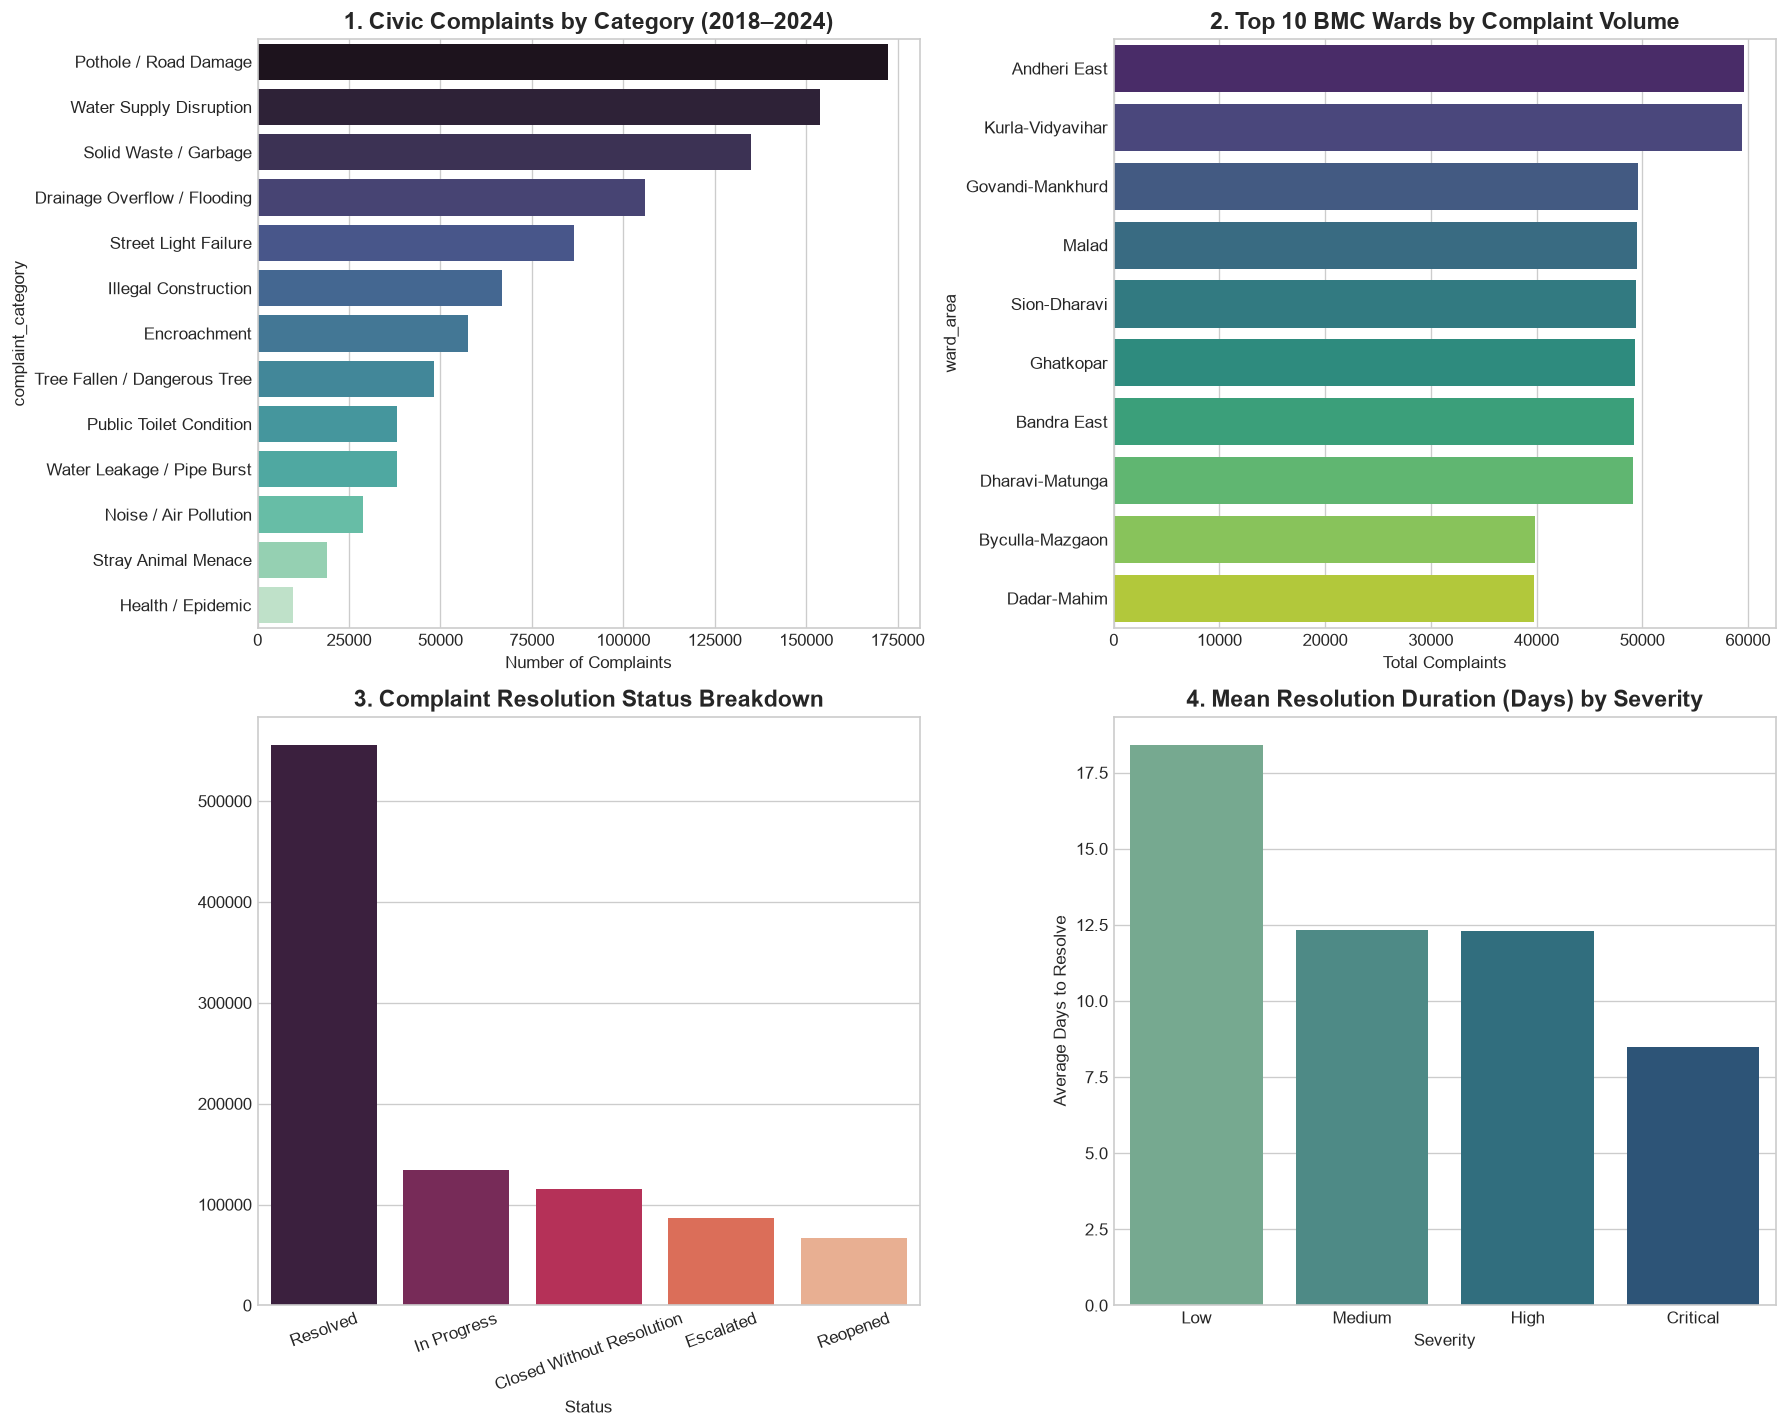

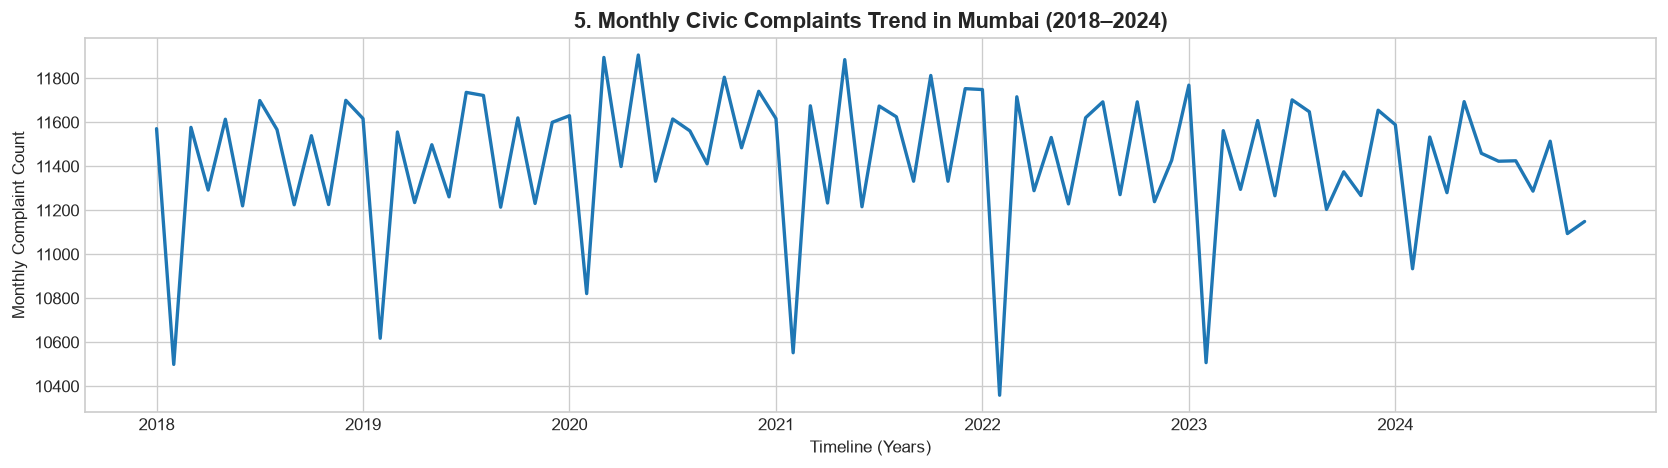

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: Category Distribution
cat_counts = df_cleaned["complaint_category"].value_counts()
sns.barplot(ax=axes[0, 0], x=cat_counts.values, y=cat_counts.index, hue=cat_counts.index, palette="mako", legend=False)
axes[0, 0].set_title("1. Civic Complaints by Category (2018–2024)")
axes[0, 0].set_xlabel("Number of Complaints")

# Plot 2: Top Wards
top_wards = df_cleaned["ward_area"].value_counts().head(10)
sns.barplot(ax=axes[0, 1], x=top_wards.values, y=top_wards.index, hue=top_wards.index, palette="viridis", legend=False)
axes[0, 1].set_title("2. Top 10 BMC Wards by Complaint Volume")
axes[0, 1].set_xlabel("Total Complaints")

# Plot 3: Status Distribution
status_counts = df_cleaned["complaint_status"].value_counts()
sns.barplot(ax=axes[1, 0], x=status_counts.index, y=status_counts.values, hue=status_counts.index, palette="rocket", legend=False)
axes[1, 0].set_title("3. Complaint Resolution Status Breakdown")
axes[1, 0].set_xlabel("Status")
axes[1, 0].tick_params(axis='x', rotation=20)

# Plot 4: Resolution Days by Severity
res_sev = df_cleaned.groupby("severity")["resolution_days"].mean().reindex(["Low", "Medium", "High", "Critical"])
sns.barplot(ax=axes[1, 1], x=res_sev.index, y=res_sev.values, hue=res_sev.index, palette="crest", legend=False)
axes[1, 1].set_title("4. Mean Resolution Duration (Days) by Severity")
axes[1, 1].set_xlabel("Severity")
axes[1, 1].set_ylabel("Average Days to Resolve")

plt.tight_layout()
plt.show()

# Longitudinal Plot
plt.figure(figsize=(14, 4))
trend = df_cleaned.groupby(["year", "month"])["complaint_count"].sum().reset_index()
trend["period"] = trend["year"].astype(str) + "-" + trend["month"].astype(str).str.zfill(2)
plt.plot(range(len(trend)), trend["complaint_count"], color="#1f77b4", linewidth=2)
ticks = range(0, len(trend), 12)
plt.xticks(ticks, trend["year"].iloc[list(ticks)])
plt.title("5. Monthly Civic Complaints Trend in Mumbai (2018–2024)", fontsize=13)
plt.xlabel("Timeline (Years)")
plt.ylabel("Monthly Complaint Count")
plt.tight_layout()
plt.show()


## 8. Star Schema Dimension & Fact Construction
### Grain:
**One row in `FACT_COMPLAINT` represents exactly one unique civic complaint registered with the BMC.**

### Dimensions:
1. `DIM_TIME` (Surrogate Key: `time_key`): Day → Month → Quarter → Year
2. `DIM_LOCATION` (Surrogate Key: `location_key`): Area (`ward_area`) → Ward (`ward`) → Zone (`zone`)
3. `DIM_CATEGORY` (Surrogate Key: `category_key`): Category → Department
4. `DIM_STATUS` (Surrogate Key: `status_key`): Resolution status, work quality, and contractor category


In [8]:
# 1. DIM_TIME
dim_time = df_cleaned[[
    "full_date", "day", "month", "month_name", "quarter", "year", "day_of_week", "is_monsoon_season"
]].drop_duplicates().sort_values("full_date").reset_index(drop=True)
dim_time["time_key"] = dim_time.index + 1
time_lookup = dict(zip(dim_time["full_date"], dim_time["time_key"]))

# 2. DIM_LOCATION
dim_location = df_cleaned[[
    "ward_code", "ward_area", "zone", "ward_type", "population_density", "ward_slum_percentage"
]].drop_duplicates().sort_values("ward_code").reset_index(drop=True)
dim_location.rename(columns={"ward_code": "ward"}, inplace=True)
dim_location["location_key"] = dim_location.index + 1
location_lookup = dict(zip(dim_location["ward"], dim_location["location_key"]))

# 3. DIM_CATEGORY
dim_category = df_cleaned[[
    "complaint_category", "department_assigned"
]].drop_duplicates().sort_values("complaint_category").reset_index(drop=True)
dim_category.rename(columns={"complaint_category": "category_name"}, inplace=True)
dim_category["category_key"] = dim_category.index + 1
category_lookup = dict(zip(dim_category["category_name"], dim_category["category_key"]))

# 4. DIM_STATUS
dim_status = df_cleaned[[
    "complaint_status", "work_quality_rating", "contractor_category"
]].drop_duplicates().sort_values(["complaint_status", "work_quality_rating"]).reset_index(drop=True)
dim_status.rename(columns={"complaint_status": "status_name"}, inplace=True)
dim_status["status_key"] = dim_status.index + 1
status_map_df = dim_status.set_index(["status_name", "work_quality_rating", "contractor_category"])["status_key"].to_dict()

# 5. FACT_COMPLAINT
fact_complaint = pd.DataFrame()
fact_complaint["complaint_id"] = df_cleaned["complaint_id"]
fact_complaint["time_key"] = df_cleaned["full_date"].map(time_lookup)
fact_complaint["location_key"] = df_cleaned["ward_code"].map(location_lookup)
fact_complaint["category_key"] = df_cleaned["complaint_category"].map(category_lookup)
status_tuples = list(zip(df_cleaned["complaint_status"], df_cleaned["work_quality_rating"], df_cleaned["contractor_category"]))
fact_complaint["status_key"] = [status_map_df[t] for t in status_tuples]

# Dimensional grain attributes
fact_complaint["complaint_channel"] = df_cleaned["complaint_channel"]
fact_complaint["complaint_time_of_day"] = df_cleaned["complaint_time_of_day"]
fact_complaint["severity"] = df_cleaned["severity"]
fact_complaint["complainant_type"] = df_cleaned["complainant_type"]
fact_complaint["property_type"] = df_cleaned["property_type"]

# Measures
fact_complaint["complaint_count"] = df_cleaned["complaint_count"]
fact_complaint["resolution_days"] = df_cleaned["resolution_days"]
fact_complaint["estimated_cost_inr"] = df_cleaned["estimated_cost_inr"]
fact_complaint["num_reassignments"] = df_cleaned["num_reassignments"]
fact_complaint["prior_complaints_count"] = df_cleaned["prior_complaints_count"]
fact_complaint["infrastructure_age_years"] = df_cleaned["infrastructure_age_years"]
fact_complaint["months_since_last_maintained"] = df_cleaned["months_since_last_maintained"]
fact_complaint["citizen_satisfied"] = df_cleaned["citizen_satisfied"]

# Audit flags
fact_complaint["has_photo_evidence"] = df_cleaned["has_photo_evidence"]
fact_complaint["has_gps_location"] = df_cleaned["has_gps_location"]
fact_complaint["media_attention"] = df_cleaned["media_attention"]
fact_complaint["politically_sensitive"] = df_cleaned["politically_sensitive"]
fact_complaint["repeat_complainant"] = df_cleaned["repeat_complainant"]
fact_complaint["site_inspected"] = df_cleaned["site_inspected"]
fact_complaint["defect_liability_claim"] = df_cleaned["defect_liability_claim"]

print("Dimension & Fact Table Shapes:")
print(f"dim_time: {dim_time.shape}")
print(f"dim_location: {dim_location.shape}")
print(f"dim_category: {dim_category.shape}")
print(f"dim_status: {dim_status.shape}")
print(f"fact_complaint: {fact_complaint.shape}")


Dimension & Fact Table Shapes:
dim_time: (2556, 9)
dim_location: (24, 7)
dim_category: (13, 3)
dim_status: (100, 4)
fact_complaint: (960000, 25)


## 9. Warehouse DDL & Automated Database Loading
We check the MySQL database state. If tables are already populated, we verify the existing record counts; otherwise, we execute the DDL script (`sql/02_create_tables.sql`) and load all dimensions and fact rows.

In [9]:
with engine.connect() as conn:
    existing_cnt = conn.execute(text("SELECT COUNT(*) FROM information_schema.tables WHERE table_schema = 'bmc_complaint_dw' AND table_name = 'fact_complaint';")).scalar()
    fact_count = 0
    if existing_cnt > 0:
        fact_count = conn.execute(text("SELECT COUNT(*) FROM fact_complaint;")).scalar()

if fact_count == len(fact_complaint):
    print(f"MySQL Data Warehouse is already fully populated with all {fact_count:,} fact records!")
else:
    print("Executing DDL and loading data warehouse...")
    sql_path = os.path.join("sql", "02_create_tables.sql") if os.path.exists("sql") else os.path.join("..", "sql", "02_create_tables.sql")
    with open(sql_path, "r", encoding="utf-8") as f:
        raw_statements = f.read().split(";")
    
    with engine.connect() as conn:
        conn.execute(text("SET FOREIGN_KEY_CHECKS = 0;"))
        for s in raw_statements:
            lines = [line for line in s.split('\n') if not line.strip().startswith('--')]
            clean_sql = '\n'.join(lines).strip()
            if clean_sql:
                conn.execute(text(clean_sql))
        conn.execute(text("SET FOREIGN_KEY_CHECKS = 1;"))
        conn.commit()

    dim_time.to_sql("dim_time", engine, if_exists="append", index=False, chunksize=1000, method="multi")
    dim_location.to_sql("dim_location", engine, if_exists="append", index=False, chunksize=1000, method="multi")
    dim_category.to_sql("dim_category", engine, if_exists="append", index=False, chunksize=1000, method="multi")
    dim_status.to_sql("dim_status", engine, if_exists="append", index=False, chunksize=1000, method="multi")
    fact_complaint.to_sql("fact_complaint", engine, if_exists="append", index=False, chunksize=20000, method="multi")
    print("Warehouse population complete!")


MySQL Data Warehouse is already fully populated with all 960,000 fact records!


## 10. Data Warehouse Validation
We run comprehensive integrity tests:
1. Row count verification
2. Primary key uniqueness
3. Foreign key referential integrity (checking for orphan records)
4. Null value checks on critical keys and measures
5. Sample 4-way Star Schema Join

In [10]:
with engine.connect() as conn:
    print("--- 1. Table Row Counts ---")
    res_counts = conn.execute(text("""
        SELECT 'fact_complaint' AS table_name, COUNT(*) AS cnt FROM fact_complaint
        UNION ALL SELECT 'dim_time', COUNT(*) FROM dim_time
        UNION ALL SELECT 'dim_location', COUNT(*) FROM dim_location
        UNION ALL SELECT 'dim_category', COUNT(*) FROM dim_category
        UNION ALL SELECT 'dim_status', COUNT(*) FROM dim_status;
    """))
    display(pd.DataFrame(res_counts.fetchall(), columns=["Table", "Record Count"]))

    print("\n--- 2. Foreign Key Referential Integrity (Orphan Record Check) ---")
    res_orphans = conn.execute(text("""
        SELECT
            (SELECT COUNT(*) FROM fact_complaint f LEFT JOIN dim_time t ON f.time_key = t.time_key WHERE t.time_key IS NULL) AS orphan_time,
            (SELECT COUNT(*) FROM fact_complaint f LEFT JOIN dim_location l ON f.location_key = l.location_key WHERE l.location_key IS NULL) AS orphan_loc,
            (SELECT COUNT(*) FROM fact_complaint f LEFT JOIN dim_category c ON f.category_key = c.category_key WHERE c.category_key IS NULL) AS orphan_cat,
            (SELECT COUNT(*) FROM fact_complaint f LEFT JOIN dim_status s ON f.status_key = s.status_key WHERE s.status_key IS NULL) AS orphan_stat;
    """))
    display(pd.DataFrame(res_orphans.fetchall(), columns=["Orphan Time", "Orphan Location", "Orphan Category", "Orphan Status"]))

    print("\n--- 3. Sample Star Schema Join (First 10 Records) ---")
    sample_df = pd.read_sql("""
        SELECT
            f.complaint_key,
            t.full_date,
            l.ward,
            l.ward_area,
            c.category_name,
            s.status_name,
            f.resolution_days,
            f.estimated_cost_inr
        FROM fact_complaint f
        JOIN dim_time t ON f.time_key = t.time_key
        JOIN dim_location l ON f.location_key = l.location_key
        JOIN dim_category c ON f.category_key = c.category_key
        JOIN dim_status s ON f.status_key = s.status_key
        ORDER BY f.complaint_key ASC
        LIMIT 10;
    """, con=conn)
    display(sample_df)


--- 1. Table Row Counts ---


,Table,Record Count
0,fact_complaint,960000
1,dim_time,2556
2,dim_location,24
3,dim_category,13
4,dim_status,100



--- 2. Foreign Key Referential Integrity (Orphan Record Check) ---


,Orphan Time,Orphan Location,Orphan Category,Orphan Status
0,0,0,0,0



--- 3. Sample Star Schema Join (First 10 Records) ---


,complaint_key,full_date,ward,ward_area,category_name,status_name,resolution_days,estimated_cost_inr
0,1,2024-09-20,A,Colaba-Fort,Illegal Construction,Resolved,37,1500.0
1,2,2024-01-02,P/N,Malad,Drainage Overflow / Flooding,Resolved,12,38600.0
2,3,2022-04-12,B,Mandvi-Masjid,Water Supply Disruption,Resolved,6,13000.0
3,4,2024-02-28,M/E,Govandi-Mankhurd,Solid Waste / Garbage,Closed Without Resolution,1,2400.0
4,5,2019-03-15,L,Kurla-Vidyavihar,Water Supply Disruption,Resolved,25,11400.0
5,6,2024-07-28,H/E,Bandra East,Pothole / Road Damage,Resolved,23,12500.0
6,7,2019-03-11,M/E,Govandi-Mankhurd,Illegal Construction,Resolved,57,2900.0
7,8,2021-02-27,M/E,Govandi-Mankhurd,Drainage Overflow / Flooding,In Progress,11,81000.0
8,9,2024-09-25,P/N,Malad,Water Supply Disruption,Escalated,1,12000.0
9,10,2019-09-14,L,Kurla-Vidyavihar,Water Supply Disruption,Reopened,28,7400.0


## 11. Implementation of All Five OLAP Operations

As required by the DWDM Week 1 curriculum, we implement all 5 core OLAP operations on the MySQL Data Warehouse:
1. **Roll-up**: Aggregating from Ward to Zone along the location hierarchy
2. **Drill-down**: Decomposing annual totals into quarterly and monthly granularity along the time hierarchy
3. **Slice**: Isolating a single dimension value (`category_name = 'Pothole / Road Damage'`)
4. **Dice**: Multi-dimensional sub-cube filtering across Category, Zone, and Year
5. **Pivot**: Dimension rotation (Ward $\times$ Category matrix) via conditional aggregation


### OLAP 1: Roll-up (Ward $\rightarrow$ Zone)
**Purpose:** Aggregate complaint metrics from the lower-level Ward grain to the higher-level Zone grain along `Area → Ward → Zone`.  
**Interpretation:** Western Zone leads in total complaint volume (355,984), followed closely by City Zone (346,769). Eastern Zone accounts for 257,247 complaints but has the highest average resolution duration (14.01 days).

In [11]:
rollup_sql = """
SELECT
    l.zone,
    COUNT(f.complaint_key) AS total_complaints,
    ROUND(AVG(f.resolution_days), 2) AS avg_resolution_days,
    ROUND(SUM(f.estimated_cost_inr), 2) AS total_cost_inr
FROM fact_complaint f
JOIN dim_location l ON f.location_key = l.location_key
GROUP BY l.zone
ORDER BY total_complaints DESC;
"""
with engine.connect() as conn:
    df_rollup = pd.read_sql(rollup_sql, con=conn)
display(df_rollup)


,zone,total_complaints,avg_resolution_days,total_cost_inr
0,Western,355984,13.47,3.886168e+09
1,City,346769,13.80,3.797657e+09
2,Eastern,257247,14.01,2.818352e+09


### OLAP 2: Drill-down (Year $\rightarrow$ Quarter $\rightarrow$ Month for Year 2024)
**Purpose:** Decompose annual 2024 complaint metrics down into quarterly and monthly details along `Year → Quarter → Month`.  
**Interpretation:** Reveals a critical operational insight: resolution durations dramatically rise from ~12.1 days in dry months to 16.55 – 16.94 days during monsoon months (June–September) due to waterlogging and flooding disruptions.

In [12]:
drilldown_sql = """
SELECT
    t.year,
    t.quarter,
    t.month,
    t.month_name,
    SUM(f.complaint_count) AS total_complaints,
    ROUND(AVG(f.resolution_days), 2) AS avg_resolution_days
FROM fact_complaint f
JOIN dim_time t ON f.time_key = t.time_key
WHERE t.year = 2024
GROUP BY t.year, t.quarter, t.month, t.month_name
ORDER BY t.quarter, t.month;
"""
with engine.connect() as conn:
    df_drilldown = pd.read_sql(drilldown_sql, con=conn)
display(df_drilldown)


,year,quarter,month,month_name,total_complaints,avg_resolution_days
0,2024,1,1,January,11589.0,12.19
1,2024,1,2,February,10934.0,12.23
2,2024,1,3,March,11533.0,12.26
3,2024,2,4,April,11280.0,12.05
4,2024,2,5,May,11694.0,12.23
5,2024,2,6,June,11459.0,16.55
6,2024,3,7,July,11423.0,16.68
7,2024,3,8,August,11425.0,16.78
8,2024,3,9,September,11287.0,16.94
9,2024,4,10,October,11514.0,12.14


### OLAP 3: Slice (Category = 'Pothole / Road Damage')
**Purpose:** Slice the data cube by fixing the Complaint Category dimension strictly to `'Pothole / Road Damage'`.  
**Interpretation:** Ward K/E (Andheri East) and Ward L (Kurla-Vidyavihar) report the highest road damage complaints (>10,500 each), pinpointing key arterial corridors requiring road resurfacing.

In [13]:
slice_sql = """
SELECT
    l.ward,
    l.ward_area,
    l.zone,
    SUM(f.complaint_count) AS pothole_complaints,
    ROUND(AVG(f.resolution_days), 2) AS avg_resolution_days
FROM fact_complaint f
JOIN dim_location l ON f.location_key = l.location_key
JOIN dim_category c ON f.category_key = c.category_key
WHERE c.category_name = 'Pothole / Road Damage'
GROUP BY l.ward, l.ward_area, l.zone
ORDER BY pothole_complaints DESC;
"""
with engine.connect() as conn:
    df_slice = pd.read_sql(slice_sql, con=conn)
display(df_slice.head(10))


,ward,ward_area,zone,pothole_complaints,avg_resolution_days
0,K/E,Andheri East,Western,10668.0,15.05
1,L,Kurla-Vidyavihar,Eastern,10596.0,18.17
2,H/E,Bandra East,Western,8901.0,15.17
3,M/E,Govandi-Mankhurd,Eastern,8894.0,14.99
4,G/N,Dharavi-Matunga,City,8880.0,18.11
5,P/N,Malad,Western,8875.0,15.20
6,F/N,Sion-Dharavi,City,8864.0,18.35
7,N,Ghatkopar,Eastern,8734.0,15.33
8,E,Byculla-Mazgaon,City,7285.0,15.55
9,D,Worli-Prabhadevi,City,7157.0,13.09


### OLAP 4: Dice (3 Categories, 2 Suburban Zones, Year 2024)
**Purpose:** Extract a sub-cube by restricting Category to top 3 utility issues, Zone to suburban zones, and Year to 2024.  
**Interpretation:** Western suburbs experience greater pothole (9,107) and water supply (8,052) issues than Eastern suburbs, while Eastern suburbs experience longer average resolution delays (15.64 days for potholes).

In [14]:
dice_sql = """
SELECT
    t.year,
    l.zone,
    c.category_name,
    SUM(f.complaint_count) AS total_complaints,
    ROUND(AVG(f.resolution_days), 2) AS avg_resolution_days
FROM fact_complaint f
JOIN dim_location l ON f.location_key = l.location_key
JOIN dim_category c ON f.category_key = c.category_key
JOIN dim_time t ON f.time_key = t.time_key
WHERE c.category_name IN ('Pothole / Road Damage', 'Water Supply Disruption', 'Drainage Overflow / Flooding')
  AND l.zone IN ('Western', 'Eastern')
  AND t.year = 2024
GROUP BY t.year, l.zone, c.category_name
ORDER BY l.zone, total_complaints DESC;
"""
with engine.connect() as conn:
    df_dice = pd.read_sql(dice_sql, con=conn)
display(df_dice)


,year,zone,category_name,total_complaints,avg_resolution_days
0,2024,Eastern,Pothole / Road Damage,6450.0,15.64
1,2024,Eastern,Water Supply Disruption,5903.0,9.33
2,2024,Eastern,Drainage Overflow / Flooding,3993.0,12.73
3,2024,Western,Pothole / Road Damage,9107.0,15.15
4,2024,Western,Water Supply Disruption,8052.0,9.18
5,2024,Western,Drainage Overflow / Flooding,5524.0,12.15


### OLAP 5: Pivot (Ward $\times$ Category Matrix via Conditional Aggregation)
**Purpose:** Cross-tabulate Ward against top complaint categories, rotating categorical rows into dedicated metric columns.  
**Interpretation:** Displays a direct side-by-side comparison across all 24 wards, identifying which municipal divisions suffer disproportionately from roads, water supply, or solid waste.

In [15]:
pivot_sql = """
SELECT
    l.ward,
    l.ward_area,
    SUM(CASE WHEN c.category_name = 'Pothole / Road Damage' THEN f.complaint_count ELSE 0 END) AS pothole_roads,
    SUM(CASE WHEN c.category_name = 'Water Supply Disruption' THEN f.complaint_count ELSE 0 END) AS water_supply,
    SUM(CASE WHEN c.category_name = 'Solid Waste / Garbage' THEN f.complaint_count ELSE 0 END) AS solid_waste,
    SUM(CASE WHEN c.category_name = 'Drainage Overflow / Flooding' THEN f.complaint_count ELSE 0 END) AS drainage_flooding,
    SUM(f.complaint_count) AS total_ward_complaints
FROM fact_complaint f
JOIN dim_location l ON f.location_key = l.location_key
JOIN dim_category c ON f.category_key = c.category_key
GROUP BY l.ward, l.ward_area
ORDER BY total_ward_complaints DESC;
"""
with engine.connect() as conn:
    df_pivot = pd.read_sql(pivot_sql, con=conn)
display(df_pivot.head(10))


,ward,ward_area,pothole_roads,water_supply,solid_waste,drainage_flooding,total_ward_complaints
0,K/E,Andheri East,10668.0,9540.0,8485.0,6638.0,59673.0
1,L,Kurla-Vidyavihar,10596.0,9620.0,8328.0,6515.0,59459.0
2,M/E,Govandi-Mankhurd,8894.0,7998.0,6919.0,5412.0,49648.0
3,P/N,Malad,8875.0,7940.0,7020.0,5362.0,49548.0
4,F/N,Sion-Dharavi,8864.0,7983.0,7020.0,5468.0,49375.0
5,N,Ghatkopar,8734.0,7846.0,6960.0,5569.0,49316.0
6,H/E,Bandra East,8901.0,7832.0,6965.0,5438.0,49269.0
7,G/N,Dharavi-Matunga,8880.0,7815.0,6954.0,5455.0,49162.0
8,E,Byculla-Mazgaon,7285.0,6335.0,5563.0,4324.0,39839.0
9,G/S,Dadar-Mahim,7146.0,6277.0,5676.0,4405.0,39768.0


## 12. Summary of Week 1 Deliverables & Planned Mining Tasks
### Completed in Week 1:
- Inspected raw CSV files and established metadata dictionary
- Built data profiling pipeline and validated data quality
- Designed a star schema (`FACT_COMPLAINT`, `DIM_TIME`, `DIM_LOCATION`, `DIM_CATEGORY`, `DIM_STATUS`)
- Implemented automated Python/Pandas ETL loading 960,000 records into MySQL
- Executed validation checks confirming 100% referential integrity
- Implemented and interpreted all 5 core OLAP operations

### Planned Data Mining Tasks (Next Phase):
1. **Complaint Category Classification:** Multi-class classification using NLP and tabular metadata
2. **Ward Clustering:** Unsupervised k-means clustering to segment wards by infrastructure failure patterns
3. **Complaint-Cause Association Rule Mining:** Apriori / FP-Growth mining of co-occurring civic complaints
4. **Recurrence & Satisfaction Prediction:** Supervised classification predicting citizen satisfaction (`citizen_satisfied`)
